# (2) Example_MNIST_CNN_Load

Questo notebook contiene un esempio su come caricare una Convolutional Neural Network (CNN) giá allenarla per poterla poi usare per _inferenza_.

## 1. Setup and Imports

Importiamo le librarie che ci serviranno

In [1]:
# Importazione delle librerie fondamentali per il calcolo tensoriale e la gestione della rete neurale.
# L'ambiente delle dipendenze deve essere speculare a quello utilizzato durante la fase di addestramento.
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import datasets, transforms
from tqdm import tqdm

# Librerie usate nella sezione 8 (copia delle reti e data augmentation).
import copy
import math
import torch.nn.functional as F

# Lavagna interattiva (file lavagna.py nella stessa cartella), usata nelle sezioni 7 e 9.
from lavagna import apri_lavagna

## 2. Data Preparation

Come per l'allenamento, é necessario avere accesso al dataset (e.g. MNIST) per fornirlo in ingresso alla rete.

In [2]:
# Inizializzazione, download (se mancante in locale) e partizionamento del dataset MNIST.

# Inference batch size
batch_size = 64

# Load the MNIST training set
mnist_data = datasets.MNIST("./", download=True, train=True,
                              transform=transforms.Compose([
                                transforms.ToTensor(),
                                transforms.Normalize((0.1307,), (0.3081,))  
                                ]),
                              target_transform=transforms.Compose([
                                lambda x:torch.tensor([x]), 
                                lambda x:torch.nn.functional.one_hot(x,10).float(),
                                lambda x:x.squeeze(),
                                ]))

# Load the MNIST test set
mnist_test = datasets.MNIST("./", download=True, train=False,
                              transform=transforms.Compose([
                                transforms.ToTensor(),
                                transforms.Normalize((0.1307,), (0.3081,))  
                                ]),
                              target_transform=transforms.Compose([
                                lambda x:torch.tensor([x]), 
                                lambda x:torch.nn.functional.one_hot(x,10).float(),
                                lambda x:x.squeeze(),
                                ]))

# Anche se il modello non deve più studiare, l'istanza del DataLoader per il subset di Test 
# è strettamente necessaria per fornire i dati in ingresso durante la successiva fase di inferenza.

# Split dataset into training and validation and create data loaders
ds_train, ds_val = torch.utils.data.random_split(mnist_data, [0.8, 0.2])
mnist_loader_train = torch.utils.data.DataLoader(ds_train, batch_size=batch_size, shuffle=True)
mnist_loader_val = torch.utils.data.DataLoader(ds_val, batch_size=batch_size, shuffle=False)

# Create test set loader
mnist_loader_test = torch.utils.data.DataLoader(mnist_test, batch_size=batch_size, shuffle=False)
N_test = len(mnist_loader_test.dataset)

## 3. Define the CNN Model

Se abbiamo una rete giá allenata, quello che é stato salvato sono i valori di tutte le variabili interne alla rete. Dobbiamo comunque definire nel nostro nuovo script o notebook la struttura della rete in modo che quando le variabili vengono caricate il compilatore Python sappia dove a cosa corrisponde ogni variabile. Nel seguito quindi la stessa ddefinizione di rete CNN che abbiamo usato nel training.

In [3]:
# Definizione della topologia della Rete Neurale Convoluzionale (CNN).
# È imperativo che l'architettura dichiarata in questa sede sia strutturalmente identica 
# a quella del modello originale, per consentire la perfetta mappatura dei pesi pre-addestrati.

# Define the CNN topology
def mnist_cnn():
    return torch.nn.Sequential(
        torch.nn.Conv2d(1, 8, 3, padding='valid', stride=2),
        torch.nn.ReLU(),
        torch.nn.Conv2d(8, 16, 3, padding='valid', stride=2),
        torch.nn.ReLU(),
        torch.nn.Flatten(),
        torch.nn.Linear(576, 16),
        torch.nn.ReLU(),
        torch.nn.Linear(16, 10)
        )

### Rete con dropout

Per la lavagna della sezione 7 carichiamo anche la seconda rete allenata nel notebook (1). Anche in questo caso la struttura deve essere identica a quella usata nel training (sezione 3.2 del notebook 1).

In [4]:
# Definizione della CNN con dropout: stessa topologia della rete classica (2 Conv2d + 2 Linear),
# con uno strato di Dropout inserito prima del primo strato lineare (identica al notebook 1).

# Define the CNN topology with dropout
def mnist_cnn_dropout():
    return torch.nn.Sequential(
        torch.nn.Conv2d(1, 8, 3, padding='valid', stride=2),
        torch.nn.ReLU(),
        torch.nn.Conv2d(8, 16, 3, padding='valid', stride=2),
        torch.nn.ReLU(),
        torch.nn.Flatten(),
        torch.nn.Dropout(p=0.3), # Spegne il 30% dei neuroni
        torch.nn.Linear(576, 16),
        torch.nn.ReLU(),
        torch.nn.Linear(16, 10)
    )

## 4. Training and Testing Functions

Anche se non ci serve piú esplicitamente per il training, il Wrapper che avevamo definito coniente anche un'interfaccia per il testing. É quindi conveniente e coerente ri-definirlo.
Ribadiamo che la definizione di una funzione Wrapper, per quanto non rara, non é di per sé uno standard nell'allenamento di reti in Pytorch. Resta comunque vantaggioso per poter poi utilizzare il framework Cross-Sim per In-Memory Computing.

In [5]:
# Istanziazione della classe "Wrapper" architetturale.
# Sebbene la fase di training venga totalmente bypassata, questa classe espone i metodi di "forward"
# necessari per propagare l'ingresso nella rete durante l'inferenza. Inoltre, mantiene la 
# standardizzazione necessaria per l'interfacciamento con Cross-Sim nel notebook successivo.

# Wrapper for training the CNN
class SequentialWrapper():
    def __init__(self, net, loss, learning_rate=1e-3):
        self.net = net
        self.loss = loss
        self.learning_rate = learning_rate
        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=self.learning_rate)

    def forward(self, x):
        return self.net(x)
    
    def training_step(self, batch):
        self.optimizer.zero_grad()
        pred = self.forward(batch[0])
        loss = self.loss(pred, batch[1])
        loss.backward()
        self.optimizer.step()
        return loss

    def validation_step(self, batch):
        pred = self.forward(batch[0])
        loss = self.loss(pred, batch[1])
        return loss
    
    def train_epoch(self, train_loader, val_loader):
        loss_train, loss_val = 0, 0
        for minibatch in iter(train_loader):
            loss_train += self.training_step(minibatch).detach()
        for minibatch in iter(val_loader):
            loss_val += self.validation_step(minibatch).detach()
        return loss_train/len(train_loader), loss_val/len(val_loader)
    
    def train(self, train_loader, val_loader, epochs):
        loss_train, loss_val = np.zeros(epochs), np.zeros(epochs)
        for e in tqdm(range(0, epochs)):
            lt, lv = self.train_epoch(train_loader, val_loader)
            loss_train[e] = lt
            loss_val[e] = lv
        return loss_train, loss_val

# Create the wrapped PyTorch model
mnist_cnn_pt = SequentialWrapper(mnist_cnn(), torch.nn.CrossEntropyLoss())

## 5. Load Trained Network

Una volta ri-definita la struttura della rete uguale a quella che é stata allenata, possiamo leggere le variabili ottenute alla fine del _training_.


In [6]:
# Caricamento dello "State Dict" dal file locale "trained_mnist_cnn.pt".
# Questa operazione sovrascrive i pesi sinaptici inizializzati casualmente dalla funzione precedente 
# con i parametri esatti derivati dalla fase di addestramento, ripristinando il "cervello" della rete.

mnist_cnn_pt.net.load_state_dict(torch.load('trained_mnist_cnn.pt'))

<All keys matched successfully>

Carichiamo allo stesso modo i pesi della rete con dropout. Entrambe le reti vengono poi messe in modalità inferenza con `eval()`: una rete appena creata è in modalità "train" e, per la rete con dropout, il Dropout resterebbe attivo dando risultati diversi a ogni inferenza. Per la rete classica `eval()` non cambia nulla, ma la teniamo per coerenza.

In [7]:
# Creazione del Wrapper per la rete con dropout e caricamento dei pesi da "trained_mnist_cnn_dropout.pt".
mnist_cnn_dropout_pt = SequentialWrapper(mnist_cnn_dropout(), torch.nn.CrossEntropyLoss())
mnist_cnn_dropout_pt.net.load_state_dict(torch.load('trained_mnist_cnn_dropout.pt'))

# Modalità inferenza per entrambe le reti (Dropout spento).
mnist_cnn_pt.net.eval()
_ = mnist_cnn_dropout_pt.net.eval()

Testiamo con un'_inferenza_ che le variabili siano state caricate correttamente.
Poiché stiamo usando lo stesso subset dei dati (_testing_) ci aspettiamo la stessa accuratezza ottenuta alla fine del notebook `Example_MNIST_CNN_Train`.

In [8]:
# Esecuzione dell'inferenza sul set di immagini di test per validare il corretto ripristino del modello.

# Perform inference on the test set, with no analog errors
# Gli array partono vuoti: np.append aggiunge in coda i risultati di ogni batch, quindi alla fine
# contengono esattamente N_test elementi. Partendo da np.zeros(N_test) avrebbero avuto in testa
# N_test zeri "corretti" sia in y che in y_pred, gonfiando l'accuratezza.
y_pred, y, k = np.array([]), np.array([]), 0
for inputs, labels in mnist_loader_test:
    with torch.no_grad():
        output = mnist_cnn_pt.net(inputs)
        y_pred_k = output.data.detach().numpy()
        y_pred = np.append(y_pred,y_pred_k.argmax(axis=-1))
        y = np.append(y,labels.detach().numpy().argmax(axis=1))

# L'accuratezza restituita funge da test di integrità: deve corrispondere alla perfezione a quella 
# ottenuta al termine dell'addestramento originario (es. 99.09%), confermando l'assenza di corruzione dei dati.

# Evaluate accuracy
accuracy_digitalTrain_digitalTest = np.sum(y == y_pred)/len(y)
print('===========')
print('No analog errors during training, no analog errors during test')
print('Test accuracy: {:.2f}%\n'.format(accuracy_digitalTrain_digitalTest*100))

No analog errors during training, no analog errors during test
Test accuracy: 98.04%



## 6. Analisi degli Errori (Misclassifications)

Una volta valutata l'accuratezza globale, è utile osservare visivamente quali immagini la rete neurale ha "sbagliato" a classificare. Questo ci permette di capire se l'errore è dovuto a limiti intrinseci del modello o a numeri scritti in modo ambiguo.
Il codice seguente confronta i valori reali con quelli predetti, estrae gli indici in cui non combaciano e stampa a schermo alcuni esempi pratici.

Totale errori riscontrati: 196 su 10000 immagini di test.


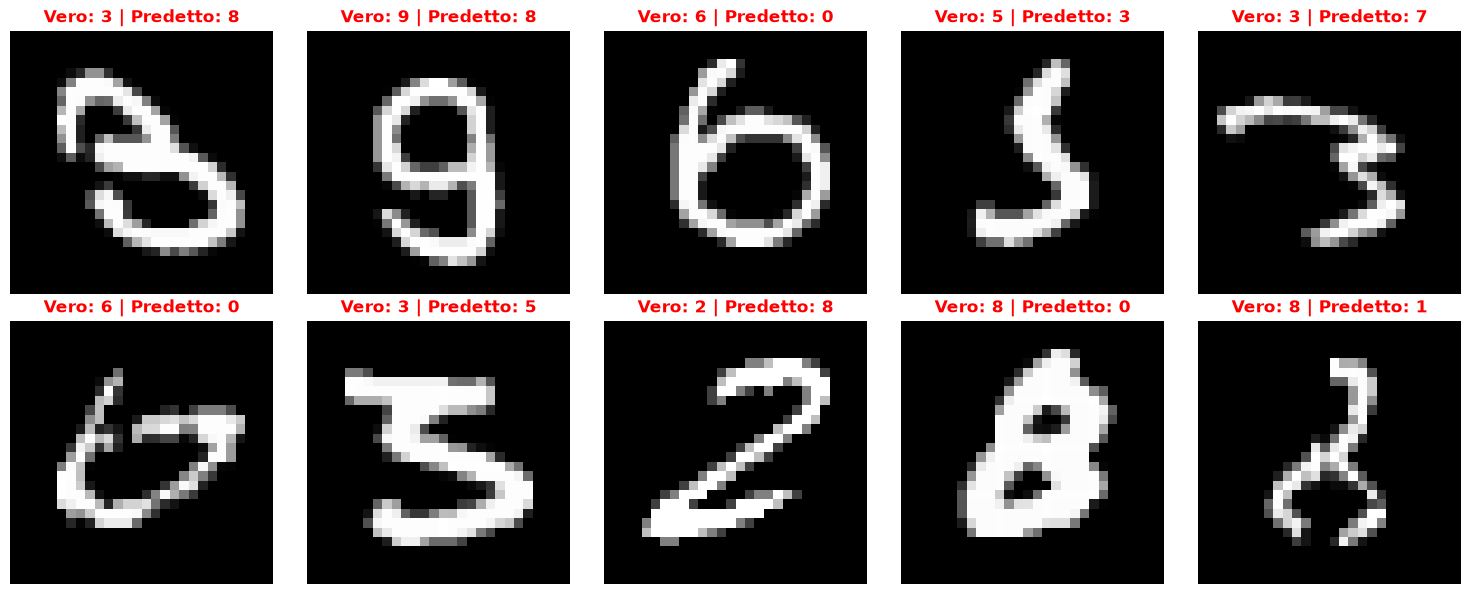

In [9]:
# Estrazione e analisi visiva delle "Misclassifications".
# Isola e decodifica i campioni del test set su cui la rete ha fallito la predizione.
# Permette un'indagine qualitativa per capire se l'errore deriva da limiti del classificatore 
# o dall'intrinseca ambiguità della grafia umana nel campione specifico.

# y e y_pred contengono già un elemento per ogni immagine di test (vedi blocco di inferenza)
y_real = y
y_predicted = y_pred

# Trova gli indici in cui la predizione non corrisponde al valore reale
error_indices = np.where(y_real != y_predicted)[0]

print(f"Totale errori riscontrati: {len(error_indices)} su {len(y_real)} immagini di test.")

# Quante immagini errate vogliamo visualizzare
num_images_to_show = 10

# Crea un layout a griglia (2 righe, 5 colonne) per evitare sovrapposizioni
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten() # Appiattisce la matrice degli assi per iterarci facilmente

for i, idx in enumerate(error_indices[:num_images_to_show]):
    image, _ = mnist_test[idx]
    image_np = image.squeeze().numpy()
    
    axes[i].imshow(image_np, cmap='gray')
    # Titolo abbreviato per risparmiare spazio (V = Vero, P = Predetto)
    axes[i].set_title(f"Vero: {int(y_real[idx])} | Predetto: {int(y_predicted[idx])}", color='red', fontsize=12, fontweight='bold')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

## 7. Inferenza Live (Lavagna Interattiva)

Ora che abbiamo testato la rete su immagini pre-esistenti, mettiamola alla prova in tempo reale. 
Eseguendo la cella si apre una finestra con una "lavagna" interattiva. Disegna un numero da 0 a 9 con il mouse e clicca su **Classifica**.

Il codice della lavagna si trova nel file `lavagna.py`, nella stessa cartella dei notebook, così può essere richiamato da qualsiasi notebook con la funzione `apri_lavagna`, passando un dizionario `{nome: rete}` con le reti da confrontare.

Il codice estrae il disegno, lo ritaglia sulla cifra, lo scala in un riquadro 20x20 e lo centra in un'immagine 28x28 (come fanno le immagini MNIST), lo normalizza e lo passa **a tutte le reti indicate**. Applicando la funzione **Softmax** all'output di ciascuna rete otteniamo la "distribuzione delle probabilità": il grafico mostra per ogni cifra le percentuali delle reti affiancate (in blu la CNN classica, in arancione la CNN con dropout), così si vede con quanta sicurezza ogni rete ha preso la sua decisione e su quali altre cifre era eventualmente indecisa. Accanto ai bottoni la finestra mostra l'immagine 28x28 che le reti ricevono davvero, per controllare che il disegno sia stato adattato come le cifre MNIST.

La cella resta in esecuzione finché la finestra è aperta: chiudila per continuare a usare il notebook.

In [10]:
# ==========================================
# 7. Inferenza Live (Finestra Pop-up Nativa 3D)
# ==========================================
# La lavagna è definita nel file "lavagna.py" (importata nella sezione 1): basta indicare le reti da confrontare.
# Le reti vengono messe automaticamente in modalità eval() (Dropout spento) prima della classificazione.
apri_lavagna({
    'CNN classica': mnist_cnn_pt,
    'CNN con dropout': mnist_cnn_dropout_pt,
})

## 8. Allenamento aggiuntivo con il dataset personale

Le due reti allenate su MNIST (sezione 5) vengono allenate ancora, per poche epoche, sui disegni raccolti con il notebook (4) (file `dataset_personale.pt`). In questo modo le reti mantengono quello che hanno imparato su MNIST e si adattano anche alla nostra grafia (*fine-tuning*).

- Si usano tutti i disegni del dataset personale; il confronto tra le reti si fa poi sulla lavagna (sezione 9), con cifre disegnate al momento.
- Si usa un learning rate più basso di quello di MNIST, per modificare poco i pesi già imparati.
- Si applica la stessa data augmentation del notebook (1) (piccole rotazioni, zoom, spostamenti e variazioni di spessore del tratto): con così pochi disegni evita che la rete li impari a memoria.
- Le reti della sezione 5 non vengono modificate: si allenano due copie, `mnist_cnn_personale_pt` e `mnist_cnn_dropout_personale_pt`.

In [11]:
# Allenamento aggiuntivo (fine-tuning) delle due reti MNIST sul dataset personale.
_ = torch.manual_seed(0)

EPOCHE_PERSONALE = 30     # poche epoche: le reti sanno già riconoscere le cifre
LR_PERSONALE = 3e-4       # learning rate più basso di quello usato su MNIST (1e-3)

# --- Caricamento del dataset personale, nello stesso formato del DataLoader MNIST (sezione 2) ---
data = torch.load('dataset_personale.pt')
x_pers = data['images'].float().unsqueeze(1) / 255.0                  # (N, 1, 28, 28), valori 0-1
x_pers = (x_pers - 0.1307) / 0.3081                                     # stessa normalizzazione di MNIST
y_pers = F.one_hot(data['labels'], 10).float()                         # etichette one-hot

pers_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(x_pers, y_pers), batch_size=16, shuffle=True)
print('Disegni personali usati per l\'allenamento:', len(y_pers))

# --- Data augmentation (stesse funzioni della sezione 5.2 del notebook 1) ---
BACKGROUND = (0 - 0.1307) / 0.3081   # valore del pixel nero dopo la normalizzazione

def random_affine(x, rot=15, scale=(0.85, 1.15), shift=0.12, shear=10):
    n = x.shape[0]
    angle = torch.empty(n).uniform_(-rot, rot) * math.pi / 180
    s = torch.empty(n).uniform_(*scale)
    sh = torch.empty(n).uniform_(-shear, shear) * math.pi / 180
    tx = torch.empty(n).uniform_(-shift, shift)
    ty = torch.empty(n).uniform_(-shift, shift)
    cos, sin = torch.cos(angle), torch.sin(angle)
    theta = torch.stack([torch.stack([cos / s, (-sin + torch.tan(sh)) / s, tx], 1),
                         torch.stack([sin / s, cos / s, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x - BACKGROUND, grid, align_corners=False, padding_mode='zeros') + BACKGROUND

def random_thickness(x, p_thick=0.2, p_thin=0.1):
    r = torch.rand(x.shape[0])
    thick = F.max_pool2d(x, 3, stride=1, padding=1)
    thin = -F.max_pool2d(-x, 3, stride=1, padding=1)
    out = x.clone()
    out[r < p_thick] = thick[r < p_thick]
    out[r > 1 - p_thin] = thin[r > 1 - p_thin]
    return out

def augment_batch(x):
    return random_thickness(random_affine(x))

# --- Allenamento: per ogni mini-batch si applica l'augmentation e si usa il training_step del Wrapper ---
def allena_personale(model, loader, epochs):
    model.net.train()                               # Dropout attivo durante l'allenamento
    for _ in tqdm(range(epochs)):
        for inputs, labels in loader:
            model.training_step((augment_batch(inputs), labels))
    model.net.eval()                                # di nuovo in modalità inferenza

# Copie delle reti allenate su MNIST (gli originali mnist_cnn_pt e mnist_cnn_dropout_pt restano invariati).
mnist_cnn_personale_pt = SequentialWrapper(copy.deepcopy(mnist_cnn_pt.net), torch.nn.CrossEntropyLoss(), learning_rate=LR_PERSONALE)
mnist_cnn_dropout_personale_pt = SequentialWrapper(copy.deepcopy(mnist_cnn_dropout_pt.net), torch.nn.CrossEntropyLoss(), learning_rate=LR_PERSONALE)

allena_personale(mnist_cnn_personale_pt, pers_loader, EPOCHE_PERSONALE)
allena_personale(mnist_cnn_dropout_personale_pt, pers_loader, EPOCHE_PERSONALE)

Disegni personali usati per l'allenamento: 101


100%|██████████| 30/30 [00:00<00:00, 49.87it/s]


## 9. Confronto sulla lavagna: con e senza il dataset personale

Apriamo la lavagna della sezione 7 passando tutte e quattro le reti: le due allenate solo su MNIST e le due allenate anche sul dataset personale. Disegnando una cifra, il grafico mostra affiancate le percentuali della Softmax di ogni rete, così si vede quali reti riconoscono meglio la nostra grafia e con quanta sicurezza.

La cella resta in esecuzione finché la finestra è aperta: chiudila per continuare a usare il notebook.

In [12]:
# Confronto dal vivo delle 4 reti sulla lavagna (stessa funzione della sezione 7).

apri_lavagna({
    'CNN classica (MNIST)': mnist_cnn_pt,
    'CNN con dropout (MNIST)': mnist_cnn_dropout_pt,
    'CNN classica (MNIST + personale)': mnist_cnn_personale_pt,
    'CNN con dropout (MNIST + personale)': mnist_cnn_dropout_personale_pt,
})